=== 5.1 & 5.2 Summary ===
  Train: 12048 | Val: 2582 | Test: 2582 | Features: 48

=== 5.3 Regression Benchmark (Test Set, +1h Target) ===
               Model  Test_MAE  Test_RMSE  Test_R2   MASE
          ExtraTrees    0.3622     0.5195   0.6840 0.7968
           GradBoost    0.3635     0.5204   0.6828 0.7997
        RandomForest    0.3598     0.5208   0.6824 0.7917
         Ridge(a=10)    0.4045     0.5655   0.6255 0.8900
           LinearReg    0.4059     0.5657   0.6252 0.8931
          ElasticNet    0.4030     0.5672   0.6233 0.8866
        DecisionTree    0.3910     0.5698   0.6197 0.8603
       Lasso(a=0.01)    0.4059     0.5702   0.6193 0.8930
Naive_Persistence_1h    0.4545     0.6980   0.4294 1.0000
     Seasonal_Lag24h    0.7137     1.0430  -0.2739 1.5703

=== 5.4 Classification Benchmark (>= 2.5 kW at t+1h) ===
    Classifier  Opt_Th  Precision  Recall     F1  ROC_AUC  PR_AUC  Brier
   GradBoost_C    0.31     0.5224  0.5494 0.5356   0.9157  0.5560 0.0561
RandomForest_C    0.

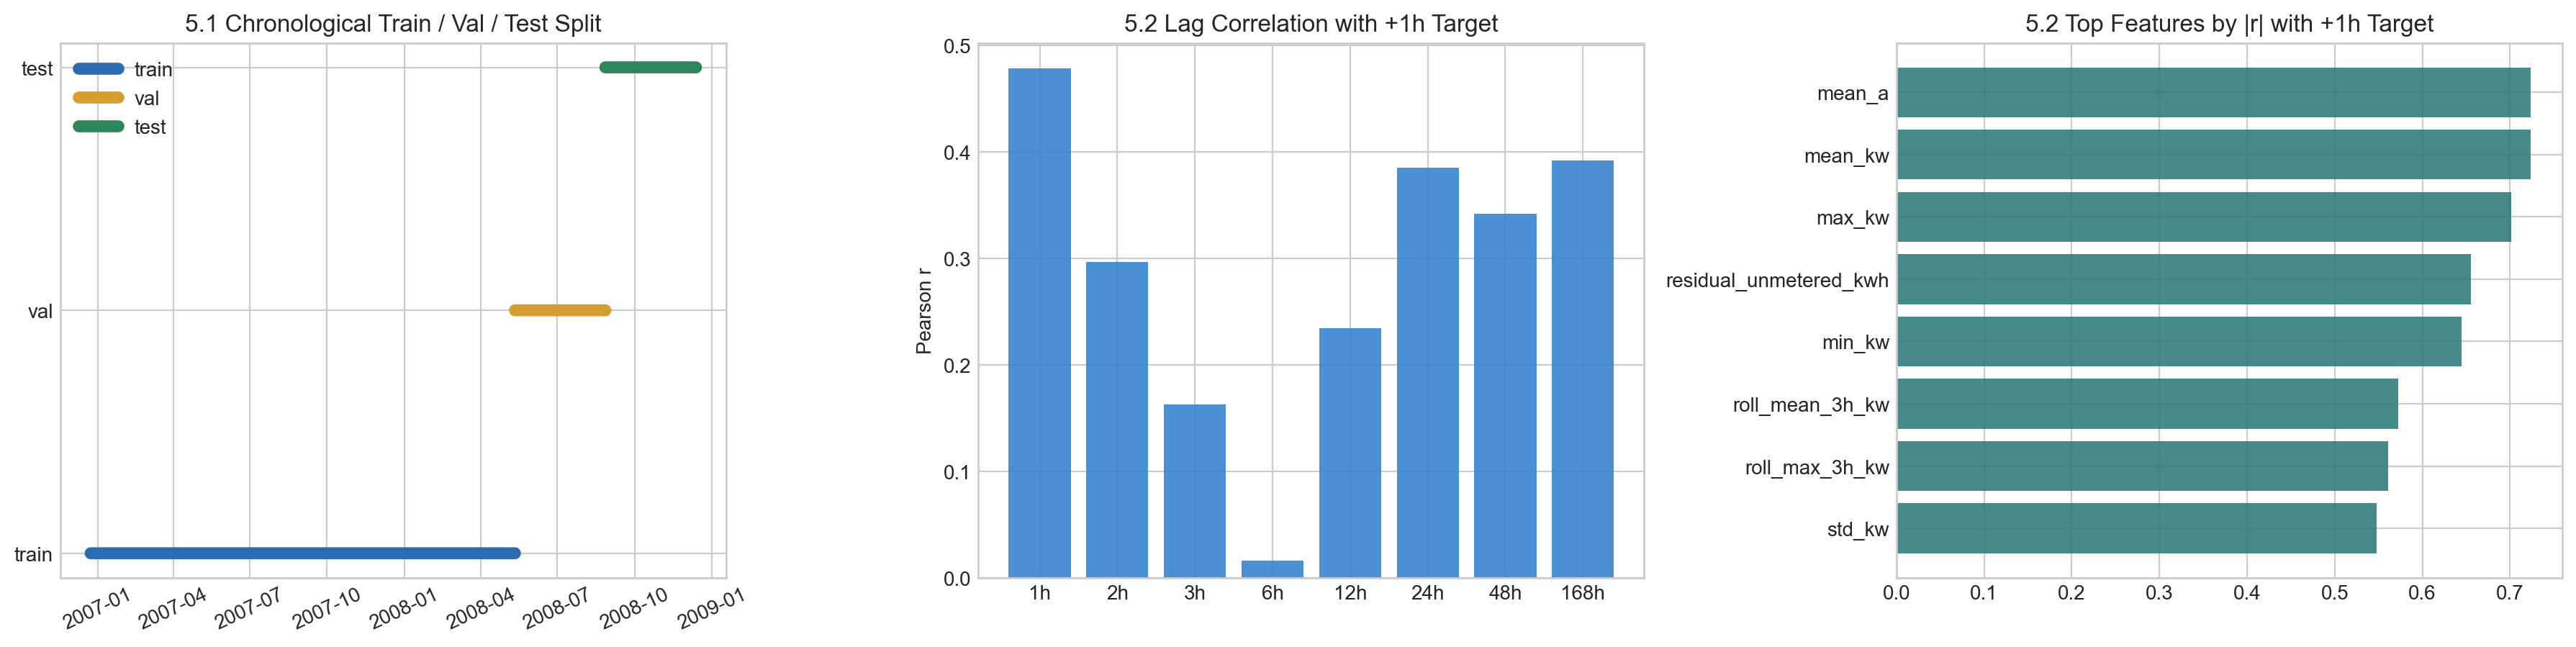

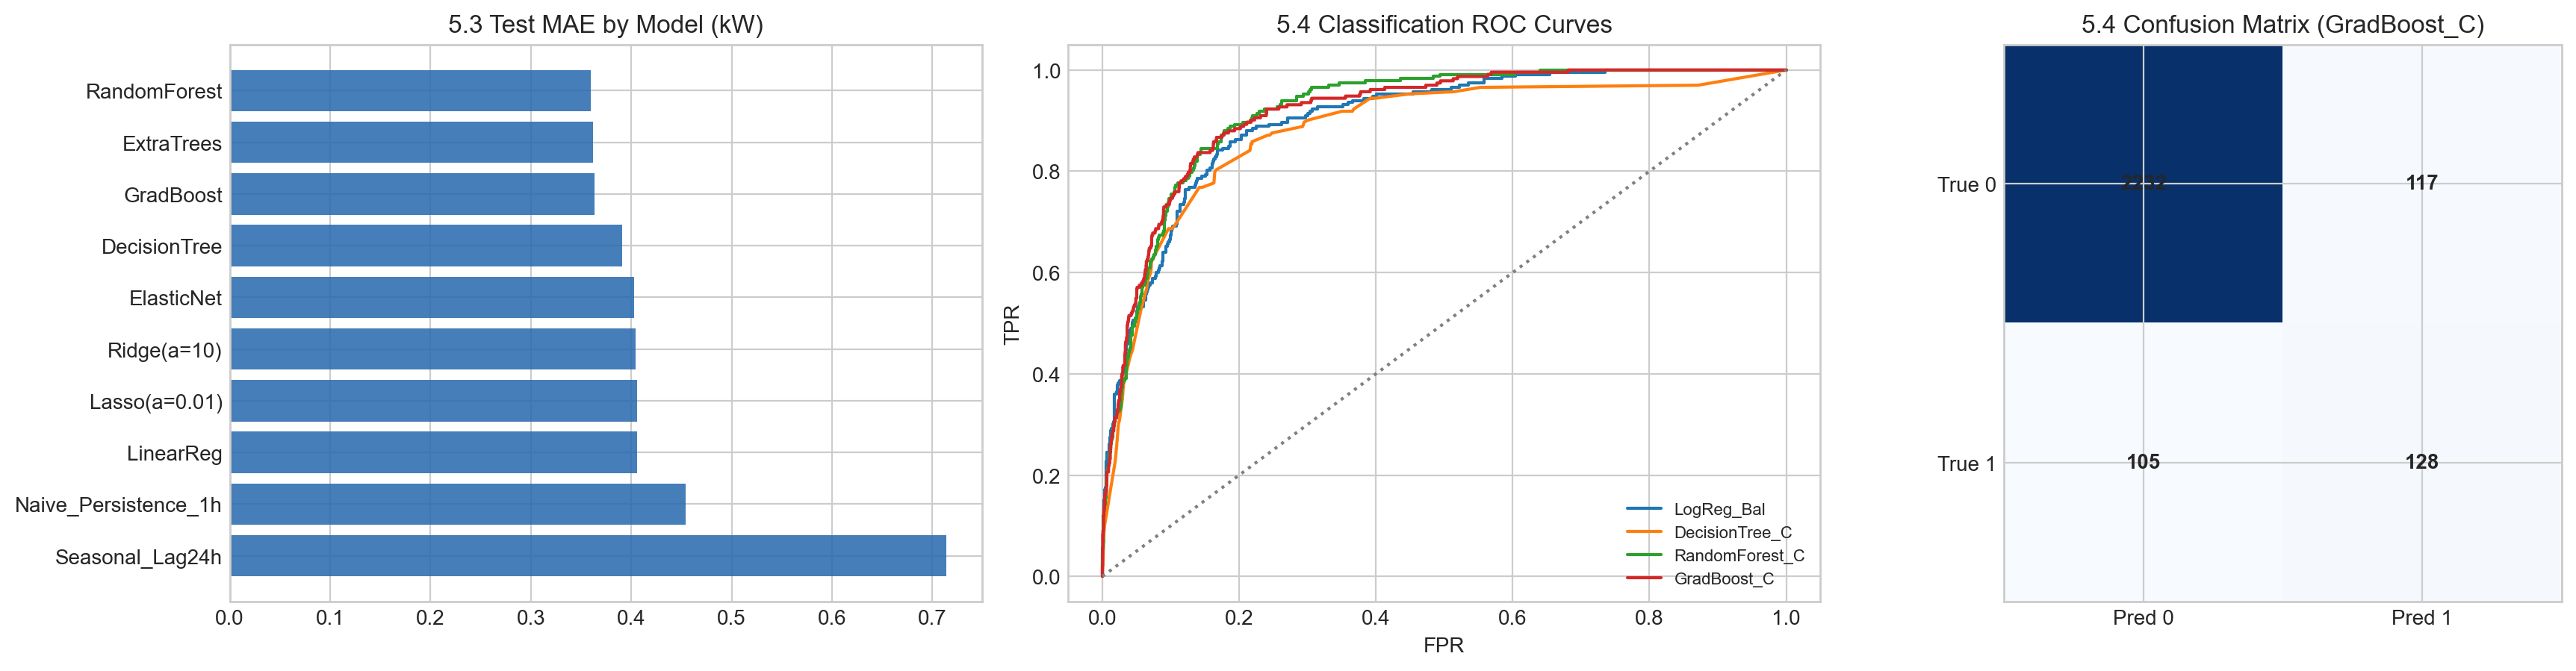

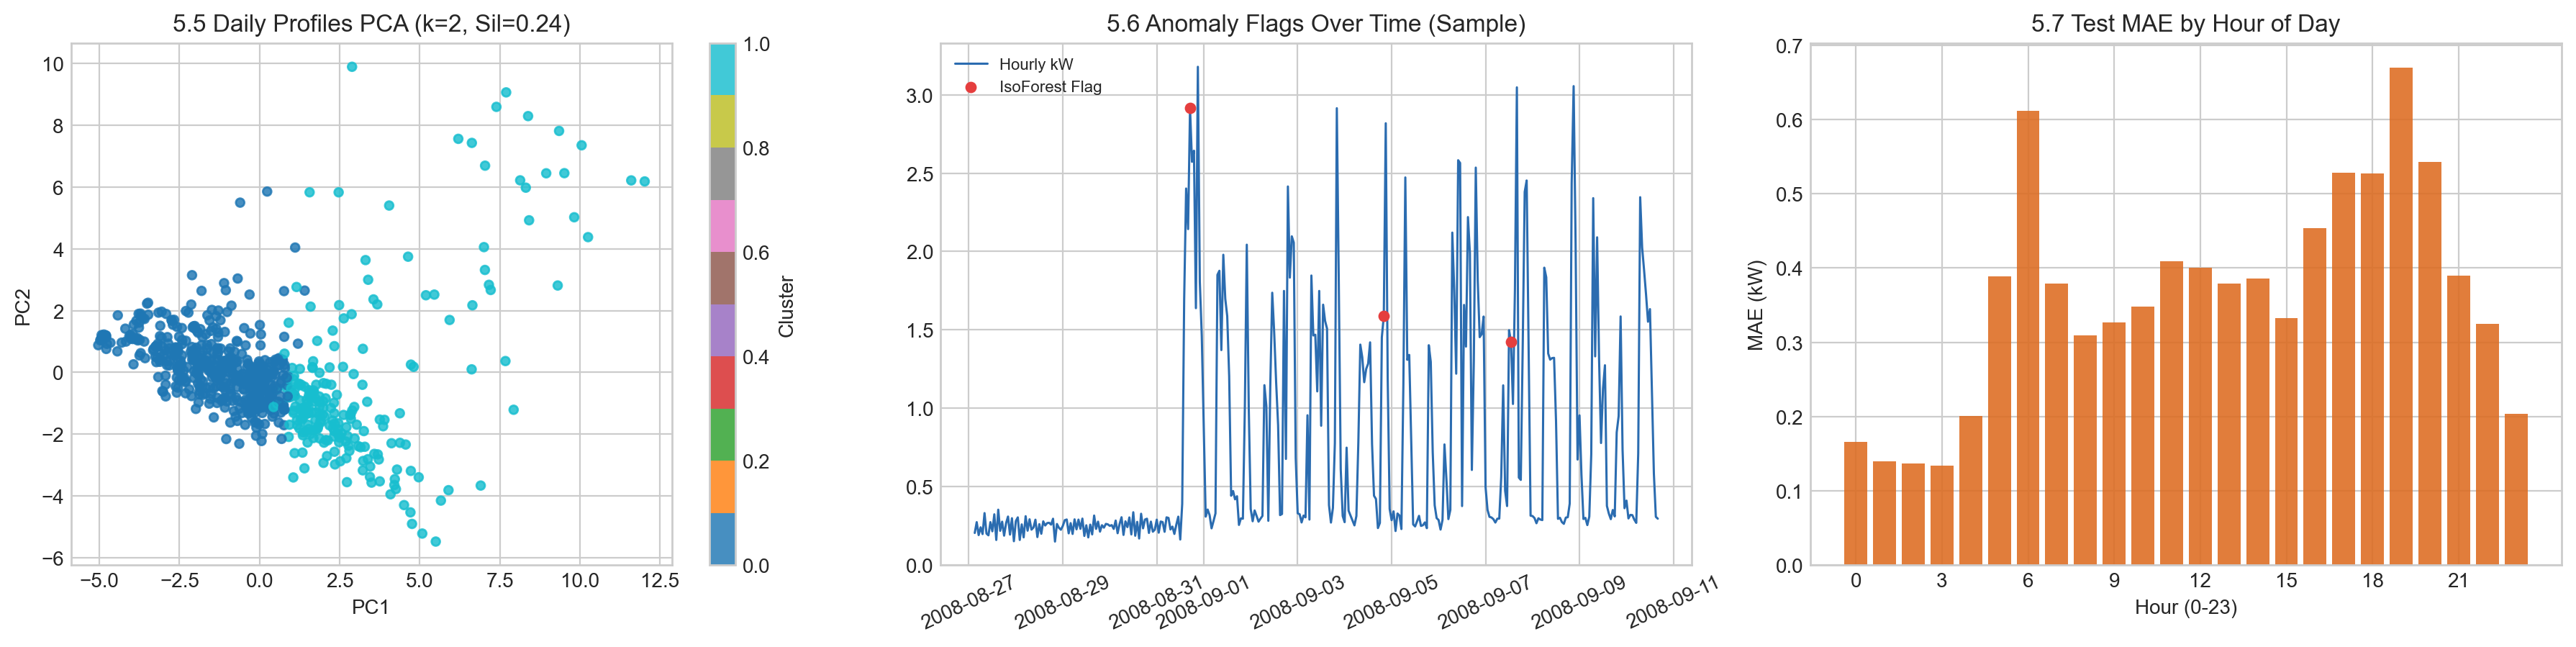

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
    IsolationForest,
)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    brier_score_loss,
    silhouette_score,
)
from sklearn.inspection import permutation_importance

# ==============================================================================
# 0. PATHS & DATA LOADING
# ==============================================================================
PROJECT_ROOT = Path(
    r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION"
)
RAW_CLEAN_PATH = PROJECT_ROOT / "cleaned_household_power.parquet"
FEAT_PATH = PROJECT_ROOT / "features_hourly_ml.parquet"

df_raw = pd.read_parquet(RAW_CLEAN_PATH)
if isinstance(df_raw.index, pd.DatetimeIndex):
    df_min = df_raw.reset_index().rename(columns={df_raw.index.name or "index": "reading_ts"})
elif "datetime" in df_raw.columns:
    df_min = df_raw.rename(columns={"datetime": "reading_ts"})
else:
    df_min = df_raw.copy()
    df_min["reading_ts"] = pd.to_datetime(df_min.index, errors="coerce")

df_min["reading_ts"] = pd.to_datetime(df_min["reading_ts"], errors="coerce")
df_min = df_min.dropna(subset=["reading_ts"]).sort_values("reading_ts").copy()

power_c = next((c for c in ["Global_active_power", "global_active_power"] if c in df_min.columns), None)
volt_c = next((c for c in ["Voltage", "voltage"] if c in df_min.columns), None)
curr_c = next((c for c in ["Global_intensity", "global_intensity"] if c in df_min.columns), None)
sm1_c = next((c for c in ["Sub_metering_1", "sub_metering_1"] if c in df_min.columns), None)
sm2_c = next((c for c in ["Sub_metering_2", "sub_metering_2"] if c in df_min.columns), None)
sm3_c = next((c for c in ["Sub_metering_3", "sub_metering_3"] if c in df_min.columns), None)

df_min["power_kw"] = pd.to_numeric(df_min[power_c], errors="coerce")
df_min["volt_v"] = pd.to_numeric(df_min[volt_c], errors="coerce") if volt_c else np.nan
df_min["curr_a"] = pd.to_numeric(df_min[curr_c], errors="coerce") if curr_c else np.nan
df_min["sm1_wh"] = pd.to_numeric(df_min[sm1_c], errors="coerce") if sm1_c else 0.0
df_min["sm2_wh"] = pd.to_numeric(df_min[sm2_c], errors="coerce") if sm2_c else 0.0
df_min["sm3_wh"] = pd.to_numeric(df_min[sm3_c], errors="coerce") if sm3_c else 0.0

# Aggregate 1-minute readings to hourly grain (mean kW * 1h = kWh)
df_min["hour_ts"] = df_min["reading_ts"].dt.floor("h")
hourly = (
    df_min.groupby("hour_ts", as_index=False)
    .agg(
        n_obs=("power_kw", "count"),
        mean_kw=("power_kw", "mean"),
        max_kw=("power_kw", "max"),
        min_kw=("power_kw", "min"),
        std_kw=("power_kw", "std"),
        mean_v=("volt_v", "mean"),
        mean_a=("curr_a", "mean"),
        sm1_kwh=("sm1_wh", lambda s: float(np.nansum(s) / 1000.0)),
        sm2_kwh=("sm2_wh", lambda s: float(np.nansum(s) / 1000.0)),
        sm3_kwh=("sm3_wh", lambda s: float(np.nansum(s) / 1000.0)),
    )
    .sort_values("hour_ts")
    .reset_index(drop=True)
)
hourly["std_kw"] = hourly["std_kw"].fillna(0.0)
hourly["total_kwh_1h"] = hourly["mean_kw"] * 1.0
hourly["sub_metered_kwh"] = hourly["sm1_kwh"] + hourly["sm2_kwh"] + hourly["sm3_kwh"]
hourly["residual_unmetered_kwh"] = (hourly["total_kwh_1h"] - hourly["sub_metered_kwh"]).clip(lower=0.0)

# ==============================================================================
# 5.1 PROBLEM FRAMING & LEAKAGE PREVENTION
# ==============================================================================
# Future targets at origin t: +1h and +24h ahead mean active power (kW)
hourly["target_t_plus_1h_kw"] = hourly["mean_kw"].shift(-1)
hourly["target_t_plus_24h_kw"] = hourly["mean_kw"].shift(-24)

# ==============================================================================
# 5.2 FEATURE ENGINEERING (STRICTLY PAST / AVAILABLE AT ORIGIN t)
# ==============================================================================
for lag_h in [1, 2, 3, 6, 12, 24, 48, 168]:
    hourly[f"lag_{lag_h}h_kw"] = hourly["mean_kw"].shift(lag_h)

for win_h in [3, 6, 24, 168]:
    r_win = hourly["mean_kw"].rolling(window=win_h, min_periods=1)
    hourly[f"roll_mean_{win_h}h_kw"] = r_win.mean()
    hourly[f"roll_std_{win_h}h_kw"] = r_win.std(ddof=0).fillna(0.0)
    hourly[f"roll_min_{win_h}h_kw"] = r_win.min()
    hourly[f"roll_max_{win_h}h_kw"] = r_win.max()

hourly["diff_1h_kw"] = hourly["mean_kw"] - hourly["lag_1h_kw"]
hourly["diff_24h_kw"] = hourly["mean_kw"] - hourly["lag_24h_kw"]
hourly["pct_chg_1h"] = (
    hourly["mean_kw"].pct_change(periods=1).replace([np.inf, -np.inf], np.nan).fillna(0.0).clip(-5.0, 5.0)
)
hourly["pct_chg_24h"] = (
    hourly["mean_kw"].pct_change(periods=24).replace([np.inf, -np.inf], np.nan).fillna(0.0).clip(-5.0, 5.0)
)

hourly["hour"] = hourly["hour_ts"].dt.hour.astype(int)
hourly["day_of_week"] = hourly["hour_ts"].dt.dayofweek.astype(int)
hourly["month"] = hourly["hour_ts"].dt.month.astype(int)
hourly["is_weekend"] = hourly["day_of_week"].isin([5, 6]).astype(int)
hourly["hour_sin"] = np.sin(2.0 * np.pi * hourly["hour"] / 24.0)
hourly["hour_cos"] = np.cos(2.0 * np.pi * hourly["hour"] / 24.0)
hourly["dow_sin"] = np.sin(2.0 * np.pi * hourly["day_of_week"] / 7.0)
hourly["dow_cos"] = np.cos(2.0 * np.pi * hourly["day_of_week"] / 7.0)

denom_kwh = hourly["total_kwh_1h"].replace(0, np.nan)
hourly["sm1_share_t"] = (hourly["sm1_kwh"] / denom_kwh).fillna(0.0).clip(0.0, 1.0)
hourly["sm2_share_t"] = (hourly["sm2_kwh"] / denom_kwh).fillna(0.0).clip(0.0, 1.0)
hourly["sm3_share_t"] = (hourly["sm3_kwh"] / denom_kwh).fillna(0.0).clip(0.0, 1.0)
hourly["residual_share_t"] = (hourly["residual_unmetered_kwh"] / denom_kwh).fillna(0.0).clip(0.0, 1.0)
hourly["high_load_flag_t"] = (hourly["mean_kw"] >= 2.5).astype(int)

df = hourly.dropna(subset=["target_t_plus_1h_kw", "target_t_plus_24h_kw", "lag_168h_kw"]).copy().reset_index(drop=True)

# Chronological 70% train / 15% val / 15% test split (zero random shuffling)
n_rows = len(df)
i_tr = int(n_rows * 0.70)
i_va = int(n_rows * 0.85)
df["split"] = "test"
df.loc[: i_tr - 1, "split"] = "train"
df.loc[i_tr : i_va - 1, "split"] = "val"

feature_cols = [
    "mean_kw", "max_kw", "min_kw", "std_kw", "mean_v", "mean_a",
    "lag_1h_kw", "lag_2h_kw", "lag_3h_kw", "lag_6h_kw", "lag_12h_kw",
    "lag_24h_kw", "lag_48h_kw", "lag_168h_kw",
    "roll_mean_3h_kw", "roll_std_3h_kw", "roll_min_3h_kw", "roll_max_3h_kw",
    "roll_mean_6h_kw", "roll_std_6h_kw", "roll_min_6h_kw", "roll_max_6h_kw",
    "roll_mean_24h_kw", "roll_std_24h_kw", "roll_min_24h_kw", "roll_max_24h_kw",
    "roll_mean_168h_kw", "roll_std_168h_kw", "roll_min_168h_kw", "roll_max_168h_kw",
    "diff_1h_kw", "diff_24h_kw", "pct_chg_1h", "pct_chg_24h",
    "hour", "day_of_week", "month", "is_weekend",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "sm1_share_t", "sm2_share_t", "sm3_share_t", "residual_share_t",
    "residual_unmetered_kwh", "high_load_flag_t",
]

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

X_train, y1_train = train_df[feature_cols], train_df["target_t_plus_1h_kw"]
X_val, y1_val = val_df[feature_cols], val_df["target_t_plus_1h_kw"]
X_test, y1_test = test_df[feature_cols], test_df["target_t_plus_1h_kw"]

# Fit preprocessing strictly on training fold
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scl", StandardScaler())]), feature_cols)
])
preprocess.fit(X_train)

# Save engineered dataset & feature dictionary
df.to_parquet(FEAT_PATH, index=False)
dict_md = [
    "# Phase 5.1 & 5.2 Leakage Audit & Feature Dictionary",
    f"- **Rows:** {len(df):,} hourly intervals | **Features:** {len(feature_cols)}",
    "- **Targets:** `target_t_plus_1h_kw` and `target_t_plus_24h_kw` (strictly future relative to origin `t`).",
    "",
    "| Feature | Meaning |",
    "| :--- | :--- |",
] + [f"| `{c}` | Feature available at or before prediction time `t` |" for c in feature_cols]
(PROJECT_ROOT / "05_1_05_2_leakage_and_feature_dictionary.md").write_text("\n".join(dict_md), encoding="utf-8")

print("=== 5.1 & 5.2 Summary ===")
print(f"  Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)} | Features: {len(feature_cols)}")

# ==============================================================================
# 5.3 SUPERVISED REGRESSION MODELS (+1H HORIZON)
# ==============================================================================
reg_estimators = {
    "LinearReg": LinearRegression(),
    "Ridge(a=10)": Ridge(alpha=10.0),
    "Lasso(a=0.01)": Lasso(alpha=0.01, max_iter=5000),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000),
    "DecisionTree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=10, n_jobs=-1, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, max_depth=12, min_samples_leaf=10, n_jobs=-1, random_state=42),
    "GradBoost": GradientBoostingRegressor(n_estimators=100, max_depth=4, learning_rate=0.06, random_state=42),
}

naive_1h = test_df["mean_kw"].to_numpy()
seas24_1h = test_df["lag_24h_kw"].fillna(test_df["mean_kw"]).to_numpy()
naive_mae = float(mean_absolute_error(y1_test, naive_1h))

reg_records = [
    {
        "Model": "Naive_Persistence_1h",
        "Test_MAE": naive_mae,
        "Test_RMSE": float(root_mean_squared_error(y1_test, naive_1h)),
        "Test_R2": float(r2_score(y1_test, naive_1h)),
        "MASE": 1.0,
    },
    {
        "Model": "Seasonal_Lag24h",
        "Test_MAE": float(mean_absolute_error(y1_test, seas24_1h)),
        "Test_RMSE": float(root_mean_squared_error(y1_test, seas24_1h)),
        "Test_R2": float(r2_score(y1_test, seas24_1h)),
        "MASE": float(mean_absolute_error(y1_test, seas24_1h) / max(naive_mae, 1e-9)),
    },
]

reg_pipes = {}
reg_preds_test = {}
for m_name, est in reg_estimators.items():
    pipe = Pipeline([("prep", preprocess), ("model", est)])
    pipe.fit(X_train, y1_train)
    p_te = pipe.predict(X_test)
    mae_val = float(mean_absolute_error(y1_test, p_te))
    reg_records.append({
        "Model": m_name,
        "Test_MAE": mae_val,
        "Test_RMSE": float(root_mean_squared_error(y1_test, p_te)),
        "Test_R2": float(r2_score(y1_test, p_te)),
        "MASE": float(mae_val / max(naive_mae, 1e-9)),
    })
    reg_pipes[m_name] = pipe
    reg_preds_test[m_name] = p_te

reg_df = pd.DataFrame(reg_records).sort_values("Test_RMSE").reset_index(drop=True)
best_reg_name = reg_df.loc[reg_df["Model"].isin(reg_estimators.keys()), "Model"].iloc[0]
best_reg_pipe = reg_pipes[best_reg_name]
best_reg_pred = reg_preds_test[best_reg_name]

print("\n=== 5.3 Regression Benchmark (Test Set, +1h Target) ===")
print(reg_df.round(4).to_string(index=False))

# ==============================================================================
# 5.4 CLASSIFICATION MODELS (ADVANCE HIGH-LOAD EVENT: >= 2.5 kW AT t+1h)
# ==============================================================================
EVENT_KW = 2.5
y_c_train = (train_df["target_t_plus_1h_kw"] >= EVENT_KW).astype(int)
y_c_val = (val_df["target_t_plus_1h_kw"] >= EVENT_KW).astype(int)
y_c_test = (test_df["target_t_plus_1h_kw"] >= EVENT_KW).astype(int)

cls_estimators = {
    "LogReg_Bal": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "DecisionTree_C": DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, class_weight="balanced", random_state=42),
    "RandomForest_C": RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=42),
    "GradBoost_C": GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.06, random_state=42),
}

cls_probs_test = {}
cls_rows = []
for c_name, cest in cls_estimators.items():
    cpipe = Pipeline([("prep", preprocess), ("clf", cest)])
    cpipe.fit(X_train, y_c_train)
    pv = cpipe.predict_proba(X_val)[:, 1]
    pt = cpipe.predict_proba(X_test)[:, 1]
    cls_probs_test[c_name] = pt

    th_grid = np.linspace(0.20, 0.80, 61)
    f1_vals = [f1_score(y_c_val, (pv >= t).astype(int), zero_division=0) for t in th_grid]
    opt_th = float(th_grid[int(np.argmax(f1_vals))])
    yhat_c = (pt >= opt_th).astype(int)

    cls_rows.append({
        "Classifier": c_name,
        "Opt_Th": round(opt_th, 2),
        "Precision": round(float(precision_score(y_c_test, yhat_c, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_c_test, yhat_c, zero_division=0)), 4),
        "F1": round(float(f1_score(y_c_test, yhat_c, zero_division=0)), 4),
        "ROC_AUC": round(float(roc_auc_score(y_c_test, pt)), 4) if len(np.unique(y_c_test)) > 1 else np.nan,
        "PR_AUC": round(float(average_precision_score(y_c_test, pt)), 4) if len(np.unique(y_c_test)) > 1 else np.nan,
        "Brier": round(float(brier_score_loss(y_c_test, pt)), 4),
    })

cls_df = pd.DataFrame(cls_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
best_cls_name = cls_df["Classifier"].iloc[0]
best_cls_th = float(cls_df["Opt_Th"].iloc[0])
best_cls_prob = cls_probs_test[best_cls_name]
best_cls_pred = (best_cls_prob >= best_cls_th).astype(int)

print(f"\n=== 5.4 Classification Benchmark (>= {EVENT_KW} kW at t+1h) ===")
print(cls_df.to_string(index=False))

# ==============================================================================
# 5.5 UNSUPERVISED LEARNING & DIMENSIONALITY REDUCTION (DAILY LOAD PROFILES)
# ==============================================================================
df["cal_date"] = df["hour_ts"].dt.date
daily_mat = df.pivot_table(index="cal_date", columns="hour", values="mean_kw", aggfunc="mean").dropna()
meta_df = df.groupby("cal_date", as_index=True).agg(
    is_weekend=("is_weekend", "max"),
    month=("month", "first"),
    daily_mean_kw=("mean_kw", "mean"),
    daily_peak_kw=("max_kw", "max"),
).loc[daily_mat.index]

X_prof_scaled = StandardScaler().fit_transform(daily_mat.to_numpy())
k_vals = [2, 3, 4, 5, 6]
sil_list = [
    float(silhouette_score(X_prof_scaled, KMeans(n_clusters=k, n_init=15, random_state=42).fit_predict(X_prof_scaled)))
    for k in k_vals
]
best_k = int(k_vals[int(np.argmax(sil_list))])

km_labels = KMeans(n_clusters=best_k, n_init=20, random_state=42).fit_predict(X_prof_scaled)
_ = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(X_prof_scaled)
db_labels = DBSCAN(eps=2.2, min_samples=6).fit_predict(X_prof_scaled)
pca_xy = PCA(n_components=2, random_state=42).fit_transform(X_prof_scaled)

meta_df["cluster"] = km_labels
meta_df["pc1"] = pca_xy[:, 0]
meta_df["pc2"] = pca_xy[:, 1]

print(f"\n=== 5.5 Daily Load Profile Clustering (Best k={best_k}, Silhouette={max(sil_list):.4f}) ===")
print(meta_df.groupby("cluster")[["daily_mean_kw", "daily_peak_kw", "is_weekend"]].mean().round(3).to_string())

# ==============================================================================
# 5.6 ANOMALY DETECTION (TIME-OF-DAY RESIDUAL, ISOLATION FOREST, LOF, OCSVM)
# ==============================================================================
tod_stats = train_df.groupby("hour")["mean_kw"].agg(["mean", "std"]).rename(columns={"mean": "tod_mu", "std": "tod_sd"})
tod_stats["tod_sd"] = tod_stats["tod_sd"].replace(0, np.nan).fillna(float(train_df["mean_kw"].std()))

anom_df = test_df.copy().reset_index(drop=True).merge(tod_stats, on="hour", how="left")
anom_df["tod_z"] = (anom_df["mean_kw"] - anom_df["tod_mu"]) / anom_df["tod_sd"]
anom_df["stat_flag"] = (anom_df["tod_z"].abs() > 3.0).astype(int)

a_cols = ["mean_kw", "max_kw", "std_kw", "diff_1h_kw", "tod_z"]
a_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("scl", StandardScaler())])
A_tr = a_pipe.fit_transform(train_df.assign(tod_z=0.0)[a_cols])
A_te = a_pipe.transform(anom_df[a_cols])

iso_m = IsolationForest(n_estimators=120, contamination=0.03, random_state=42).fit(A_tr)
lof_m = LocalOutlierFactor(n_neighbors=25, contamination=0.03, novelty=True).fit(A_tr)
svm_m = OneClassSVM(nu=0.03, kernel="rbf", gamma="scale").fit(A_tr)

anom_df["iso_score"] = -iso_m.decision_function(A_te)
anom_df["iso_flag"] = (iso_m.predict(A_te) == -1).astype(int)
anom_df["lof_flag"] = (lof_m.predict(A_te) == -1).astype(int)
anom_df["svm_flag"] = (svm_m.predict(A_te) == -1).astype(int)

c_levels = [0.01, 0.03, 0.05]
c_alert_pct = {
    c_l: float((IsolationForest(n_estimators=100, contamination=c_l, random_state=42).fit(A_tr).predict(A_te) == -1).mean() * 100.0)
    for c_l in c_levels
}

print("\n=== 5.6 Anomaly Detection Summary (Test Set) ===")
print(
    f"  Stat |z|>3: {int(anom_df['stat_flag'].sum())} | IsoForest: {int(anom_df['iso_flag'].sum())} "
    f"| LOF: {int(anom_df['lof_flag'].sum())} | OCSVM: {int(anom_df['svm_flag'].sum())}"
)

# ==============================================================================
# 5.7 EVALUATION, UNCERTAINTY & EXPLAINABILITY
# ==============================================================================
resid_test = y1_test.to_numpy() - best_reg_pred
resid_val = y1_val.to_numpy() - best_reg_pipe.predict(X_val)
q10_v, q90_v = float(np.quantile(resid_val, 0.10)), float(np.quantile(resid_val, 0.90))
low_80 = best_reg_pred + q10_v
high_80 = best_reg_pred + q90_v
cov_80 = float(np.mean((y1_test.to_numpy() >= low_80) & (y1_test.to_numpy() <= high_80)) * 100.0)

idx_sub = np.linspace(0, len(X_test) - 1, min(1500, len(X_test)), dtype=int)
perm = permutation_importance(
    best_reg_pipe, X_test.iloc[idx_sub], y1_test.iloc[idx_sub],
    n_repeats=5, random_state=42, scoring="neg_mean_absolute_error"
)
top_perm = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=True).tail(10)

err_df = test_df[["hour", "month"]].copy().reset_index(drop=True)
err_df["abs_err"] = np.abs(resid_test)
mae_hr = err_df.groupby("hour")["abs_err"].mean()
mae_mth = err_df.groupby("month")["abs_err"].mean()

print(f"\n=== 5.7 Uncertainty & Explainability ({best_reg_name}) ===")
print(f"  80% Prediction Interval Coverage: {cov_80:.2f}% | Test MAE: {mean_absolute_error(y1_test, best_reg_pred):.4f} kW")

# ==============================================================================
# COMBINED VISUAL EVIDENCE (5.1-5.2 & 5.3-5.7 MULTI-PANEL FIGURES)
# ==============================================================================
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# Fig A: 5.1 Split & 5.2 Lag Correlations + Top Features
figA, axA = plt.subplots(1, 3, figsize=(18, 4.6), dpi=200)
for sp_k, hex_c in [("train", "#2b6cb0"), ("val", "#d69e2e"), ("test", "#2f855a")]:
    sp_sub = df[df["split"] == sp_k]
    axA[0].plot(sp_sub["hour_ts"], [sp_k] * len(sp_sub), lw=6, color=hex_c, label=sp_k)
axA[0].set_title("5.1 Chronological Train / Val / Test Split")
axA[0].tick_params(axis="x", rotation=25)
axA[0].legend()

lags_show = [1, 2, 3, 6, 12, 24, 48, 168]
r_lags = [float(df[f"lag_{l}h_kw"].corr(df["target_t_plus_1h_kw"])) for l in lags_show]
axA[1].bar([f"{l}h" for l in lags_show], r_lags, color="#3182ce", alpha=0.88)
axA[1].set_title("5.2 Lag Correlation with +1h Target")
axA[1].set_ylabel("Pearson r")

top_corr = df[feature_cols].apply(lambda s: abs(float(s.corr(df["target_t_plus_1h_kw"])))).sort_values().tail(8)
axA[2].barh(top_corr.index, top_corr.values, color="#2c7a7b", alpha=0.88)
axA[2].set_title("5.2 Top Features by |r| with +1h Target")
plt.tight_layout()
plt.show()

# Fig B: 5.3 Regression MAE, 5.4 ROC & 5.4 Confusion Matrix
figB, axB = plt.subplots(1, 3, figsize=(18, 4.6), dpi=200)
m_sort = reg_df.sort_values("Test_MAE", ascending=True)
axB[0].barh(m_sort["Model"], m_sort["Test_MAE"], color="#2b6cb0", alpha=0.88)
axB[0].set_title("5.3 Test MAE by Model (kW)")
axB[0].invert_yaxis()

for cn, pr in cls_probs_test.items():
    if len(np.unique(y_c_test)) > 1:
        fpr_v, tpr_v, _ = roc_curve(y_c_test, pr)
        axB[1].plot(fpr_v, tpr_v, lw=1.5, label=cn)
axB[1].plot([0, 1], [0, 1], ":", color="gray")
axB[1].set_title("5.4 Classification ROC Curves")
axB[1].set_xlabel("FPR")
axB[1].set_ylabel("TPR")
axB[1].legend(fontsize=8)

cm_v = confusion_matrix(y_c_test, best_cls_pred)
axB[2].imshow(cm_v, cmap="Blues")
for (ri, ci), v in np.ndenumerate(cm_v):
    axB[2].text(ci, ri, str(v), ha="center", va="center", fontweight="bold")
axB[2].set_xticks([0, 1])
axB[2].set_xticklabels(["Pred 0", "Pred 1"])
axB[2].set_yticks([0, 1])
axB[2].set_yticklabels(["True 0", "True 1"])
axB[2].set_title(f"5.4 Confusion Matrix ({best_cls_name})")
plt.tight_layout()
plt.show()

# Fig C: 5.5 Silhouette & PCA Clusters, 5.6 Anomaly Overlay & 5.7 Interval/Error
figC, axC = plt.subplots(1, 3, figsize=(18, 4.6), dpi=200)
sc_p = axC[0].scatter(meta_df["pc1"], meta_df["pc2"], c=meta_df["cluster"], cmap="tab10", s=18, alpha=0.82)
axC[0].set_title(f"5.5 Daily Profiles PCA (k={best_k}, Sil={max(sil_list):.2f})")
axC[0].set_xlabel("PC1")
axC[0].set_ylabel("PC2")
plt.colorbar(sc_p, ax=axC[0], label="Cluster")

sl_a = anom_df.iloc[:350]
axC[1].plot(sl_a["hour_ts"], sl_a["mean_kw"], color="#2b6cb0", lw=1.1, label="Hourly kW")
f_a = sl_a[sl_a["iso_flag"] == 1]
axC[1].scatter(f_a["hour_ts"], f_a["mean_kw"], color="#e53e3e", s=22, zorder=4, label="IsoForest Flag")
axC[1].set_title("5.6 Anomaly Flags Over Time (Sample)")
axC[1].tick_params(axis="x", rotation=25)
axC[1].legend(fontsize=8)

axC[2].bar(mae_hr.index.astype(str), mae_hr.values, color="#dd6b20", alpha=0.88)
axC[2].set_title("5.7 Test MAE by Hour of Day")
axC[2].set_xlabel("Hour (0-23)")
axC[2].set_ylabel("MAE (kW)")
axC[2].set_xticks(range(0, 24, 3))
plt.tight_layout()
plt.show()